In [1]:
import matplotlib.pyplot as plt
import seaborn as sns

import keras
from keras.models import Sequential
from keras.layers import Dense, Conv2D , MaxPool2D , Flatten , Dropout 
from keras.preprocessing.image import ImageDataGenerator
from keras.optimizers import Adam

from sklearn.metrics import classification_report,confusion_matrix
import tensorflow as tf

import cv2
import os

import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings("ignore")
os.getcwd()

'c:\\IMAGE\\Foliage'

In [2]:
data_dir='modeldata_foliage'
labels = ['foliage_102+101', 'other_102+101']
img_size = 224  #224
def get_data(data_dir):
    data = [] 
    for label in labels: 
        path = os.path.join(data_dir, label)
        class_num = labels.index(label)
        
        cnt=0
        for img in os.listdir(path):
            #if cnt<=1000:
            try:
                img_arr = cv2.imread(os.path.join(path, img))[...,::-1] #convert BGR to RGB format
                resized_arr = cv2.resize(img_arr, (img_size, img_size)) # Reshaping images to preferred size
                data.append([resized_arr, class_num])
                cnt=cnt+1
            except Exception as e:
                print(e)
        print(label,'   --   ',cnt)
    return np.array(data)

foliage_102+101    --    950
other_102+101    --    1600


<Axes: xlabel='data', ylabel='count'>

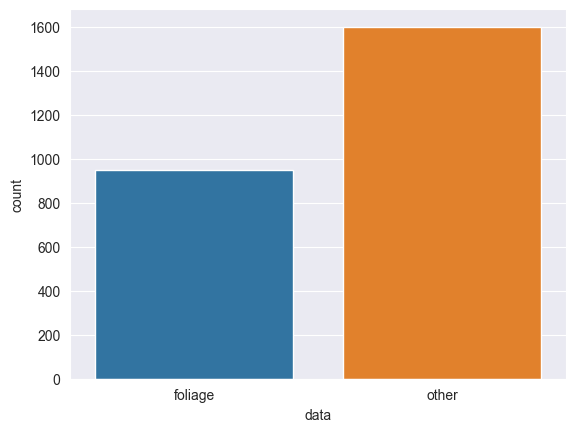

In [3]:
alldata=get_data(data_dir)

l = []
for i in alldata:
    if(i[1] == 0):
        l.append("foliage")
    else:
        l.append("other")
"""
sns.set_style('darkgrid')
sns.countplot(l)
"""
sns.set_style('darkgrid')
sns.countplot(pd.DataFrame(data=l,columns=['data']),x='data')

In [4]:
from sklearn.model_selection import train_test_split
train, val = train_test_split(alldata, test_size=0.2, random_state=7)

labels = ['building', 'other']
train  = get_data('C:/DEV/imageprocess/modeldata/main_gmap/train')
val    = get_data('C:/DEV/imageprocess/modeldata/main_gmap/test')

<Axes: xlabel='data', ylabel='count'>

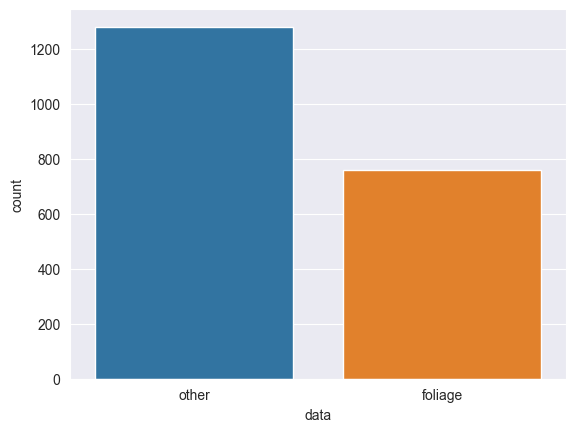

In [5]:
l = []
for i in train:
    if(i[1] == 0):
        l.append("foliage")
    else:
        l.append("other")
"""
sns.set_style('darkgrid')
sns.countplot(l)
"""
sns.set_style('darkgrid')
sns.countplot(pd.DataFrame(data=l,columns=['data']),x='data')

<Axes: xlabel='data', ylabel='count'>

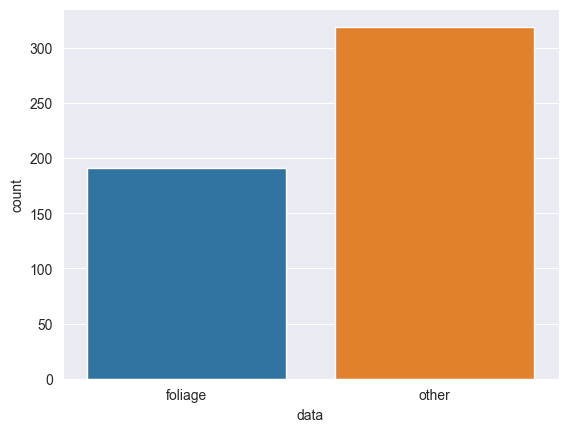

In [6]:
l = []
for i in val:
    if(i[1] == 0):
        l.append("foliage")
    else:
        l.append("other")
"""
sns.set_style('darkgrid')
sns.countplot(l)
"""
sns.set_style('darkgrid')
sns.countplot(pd.DataFrame(data=l,columns=['data']),x='data')

Text(0.5, 1.0, 'other_102+101')

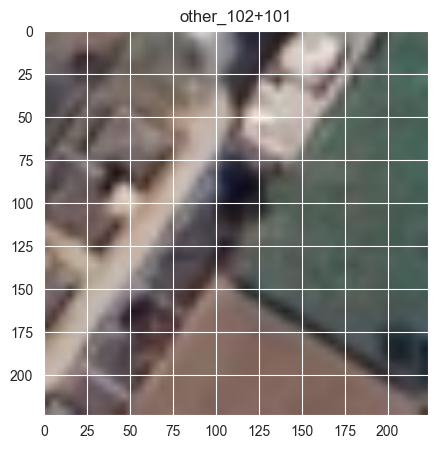

In [7]:
plt.figure(figsize = (5,5))
plt.imshow(train[5][0])
plt.title(labels[train[5][1]])

Text(0.5, 1.0, 'other_102+101')

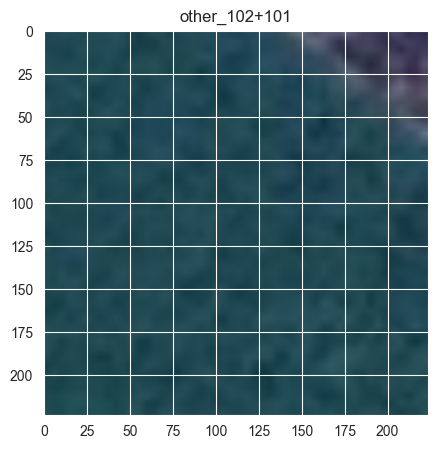

In [8]:
plt.figure(figsize = (5,5))
plt.imshow(train[0][0])
plt.title(labels[train[0][1]])

In [9]:
x_train = []
y_train = []
x_val = []
y_val = []

for feature, label in train:
    x_train.append(feature)
    y_train.append(label)

for feature, label in val:
    x_val.append(feature)
    y_val.append(label)

# Normalize the data
x_train = np.array(x_train) / 255
x_val = np.array(x_val) / 255

x_train.reshape(-1, img_size, img_size, 1)
y_train = np.array(y_train)

x_val.reshape(-1, img_size, img_size, 1)
y_val = np.array(y_val)

In [10]:
datagen = ImageDataGenerator(
        featurewise_center=False,  # set input mean to 0 over the dataset
        samplewise_center=False,  # set each sample mean to 0
        featurewise_std_normalization=False,  # divide inputs by std of the dataset
        samplewise_std_normalization=False,  # divide each input by its std
        zca_whitening=False,  # apply ZCA whitening
        rotation_range = 180,  # randomly rotate images in the range (degrees, 0 to 180)
        zoom_range = 0.2, # Randomly zoom image 
        width_shift_range=0.2,  # randomly shift images horizontally (fraction of total width)
        height_shift_range=0.2,  # randomly shift images vertically (fraction of total height)
        horizontal_flip = True,  # randomly flip images
        vertical_flip=True)  # randomly flip images

model = Sequential()
model.add(Conv2D(128,3,padding="same", activation="relu", input_shape=(224,224,3)))
model.add(MaxPool2D())

model.add(Conv2D(64, 3, padding="same", activation="relu"))
model.add(MaxPool2D())

model.add(Conv2D(32, 3, padding="same", activation="relu"))
model.add(MaxPool2D())
#model.add(Dropout(0.4))

model.add(Flatten())
model.add(Dense(128,activation="relu"))
model.add(Dense(64,activation="relu"))
model.add(Dense(32,activation="relu"))
model.add(Dense(2, activation="softmax"))

model.summary()

In [11]:
model = Sequential()
model.add(Conv2D(32,3,padding="same", activation="relu", input_shape=(224,224,3)))
model.add(MaxPool2D())

model.add(Conv2D(32, 3, padding="same", activation="relu"))
model.add(MaxPool2D())

model.add(Conv2D(64, 3, padding="same", activation="relu"))
model.add(MaxPool2D())
model.add(Dropout(0.4))

model.add(Flatten())
model.add(Dense(128,activation="relu"))
model.add(Dense(2, activation="softmax"))

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 224, 224, 32)      896       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 112, 112, 32)     0         
 )                                                               
                                                                 
 conv2d_1 (Conv2D)           (None, 112, 112, 32)      9248      
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 56, 56, 32)       0         
 2D)                                                             
                                                                 
 conv2d_2 (Conv2D)           (None, 56, 56, 64)        18496     
                                                                 
 max_pooling2d_2 (MaxPooling  (None, 28, 28, 64)       0

In [12]:
opt = Adam(lr=0.000001)
model.compile(optimizer = opt , loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True) , metrics = ['accuracy'])

In [13]:
history = model.fit(x_train,y_train,epochs = 500 , validation_data = (x_val, y_val))

Epoch 1/500
64/64 [==============================] - 50s 779ms/step - loss: 0.6457 - accuracy: 0.6240 - val_loss: 0.6188 - val_accuracy: 0.6255
Epoch 2/500
64/64 [==============================] - 53s 832ms/step - loss: 0.6089 - accuracy: 0.6279 - val_loss: 0.6075 - val_accuracy: 0.6255
Epoch 3/500
64/64 [==============================] - 53s 829ms/step - loss: 0.6046 - accuracy: 0.6279 - val_loss: 0.6049 - val_accuracy: 0.6255
Epoch 4/500
64/64 [==============================] - 53s 825ms/step - loss: 0.6013 - accuracy: 0.6279 - val_loss: 0.6023 - val_accuracy: 0.6255
Epoch 5/500
64/64 [==============================] - 53s 821ms/step - loss: 0.5982 - accuracy: 0.6279 - val_loss: 0.5995 - val_accuracy: 0.6255
Epoch 6/500
64/64 [==============================] - 52s 820ms/step - loss: 0.5961 - accuracy: 0.6279 - val_loss: 0.5966 - val_accuracy: 0.6255
Epoch 7/500
64/64 [==============================] - 53s 823ms/step - loss: 0.5924 - accuracy: 0.6279 - val_loss: 0.5933 - val_accuracy:

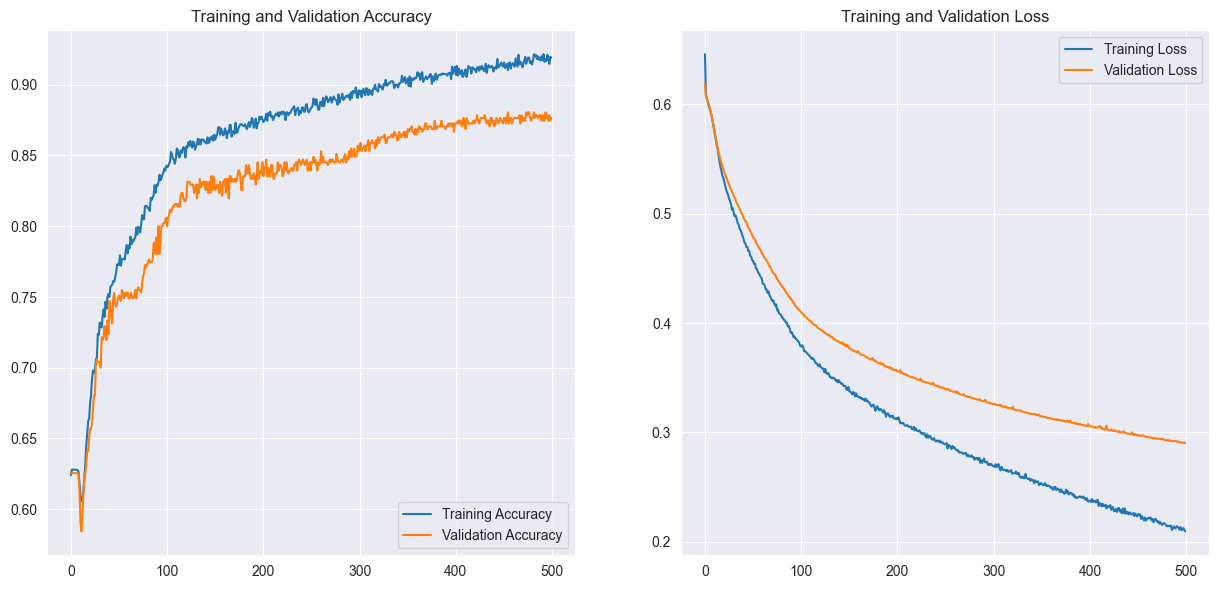

In [14]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(500)

plt.figure(figsize=(15, 15))
plt.subplot(2, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy'),
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(2, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

In [15]:
#predictions = (model.predict(x_val) > 0.5).astype("int32")
predict_x = model.predict(x_val)
classes_x=np.argmax(predict_x,axis=1)
print(classification_report(y_val, classes_x, target_names = ['Foliage (Class 0)','Other (Class 1)']))

16/16 [==============================] - 3s 205ms/step
                   precision    recall  f1-score   support

Foliage (Class 0)       0.83      0.84      0.84       191
  Other (Class 1)       0.91      0.90      0.90       319

         accuracy                           0.88       510
        macro avg       0.87      0.87      0.87       510
     weighted avg       0.88      0.88      0.88       510



In [16]:
#from tensorflow.keras.models import save_model
#save_model(model, 'modeldata_foliage/foliage-detector-v11_103.h5')

from tensorflow.keras.models import load_model
model_loaded = load_model('C:/DEV/imageprocess/modeldata/building-detector-v1.h5')

predict_x = model_loaded.predict(x_val)
classes_x=np.argmax(predict_x,axis=1)
print(classification_report(y_val, classes_x, target_names = ['Building (Class 0)','Other (Class 1)']))

In [17]:
'''
import os
cwd = os.getcwd()
os.environ["PATH"] += os.pathsep + "C:/LAB/supporting/DOT"
#os.environ["PATH"] += os.pathsep + cwd + "\\DOT"

import keras

from tensorflow.keras.models import load_model
model_loaded = load_model('C:/DEV/imageprocess/modeldata/building-detector-v7.h5')

keras.utils.plot_model(model_loaded, "architecture.png", show_shapes=True)
'''

'\nimport os\ncwd = os.getcwd()\nos.environ["PATH"] += os.pathsep + "C:/LAB/supporting/DOT"\n#os.environ["PATH"] += os.pathsep + cwd + "\\DOT"\n\nimport keras\n\nfrom tensorflow.keras.models import load_model\nmodel_loaded = load_model(\'C:/DEV/imageprocess/modeldata/building-detector-v7.h5\')\n\nkeras.utils.plot_model(model_loaded, "architecture.png", show_shapes=True)\n'

In [18]:
#%history -g -f filename